# ML Mini Project

Build a machine learning model that predicts the type of people who survived the Titanic <br>
shipwreck using passenger data (i.e. name, age, gender, socio-economic class, etc.). <br>
Dataset Link: Titanic Competition Dataset (Kaggle) <br>
https://www.kaggle.com/competitions/titanic/data 

#### Step 1: Import required libraries

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

#### Step 2: Load the dataset

In [41]:
df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### Step 3: Explore the dataset

In [42]:
print("Dataset Shape:\n", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
 (891, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare    

#### Step 4: Data preprocessing
Handle missing values and convert gender into numerical values.

In [43]:
# Fill missing age values with median
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing embarked values with mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Convert gender into numeric values
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})

# Remove Cabin column
df = df.drop(columns=["Cabin"])

# Convert embarked into numeric values
df = pd.get_dummies(df, columns=["Embarked"], dtype=int)

print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked_C     0
Embarked_Q     0
Embarked_S     0
dtype: int64


#### Step 5: Data visualization
Visualize survival based on gender and passenger class.

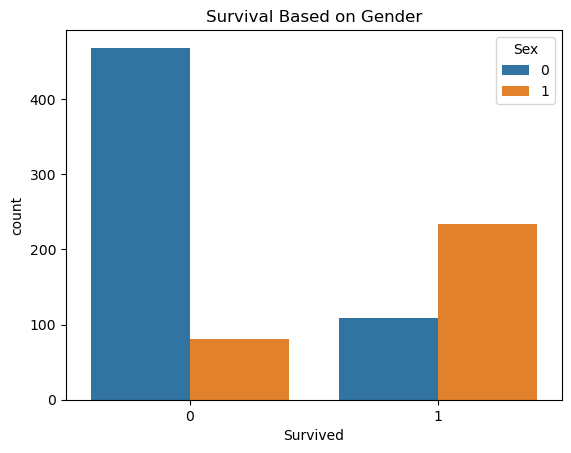

In [44]:
sns.countplot(data=df, x="Survived", hue="Sex")
plt.title("Survival Based on Gender")
plt.show()

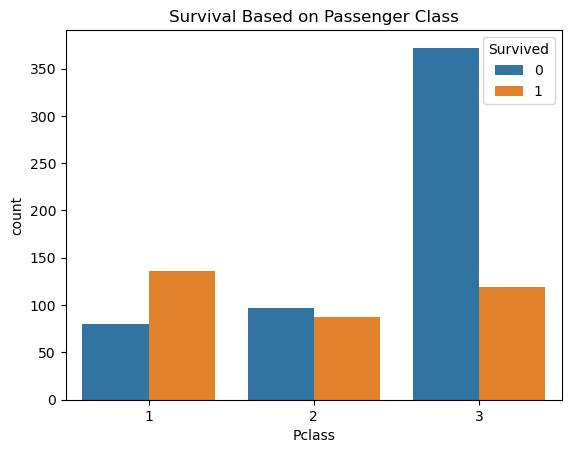

In [45]:
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Survival Based on Passenger Class")
plt.show()

#### Step 6: Select features and target

In [46]:
features = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked_C",
    "Embarked_Q", "Embarked_S"
]

X = df[features]
y = df["Survived"]

X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,0
2,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,3,0,35.0,0,0,8.0500,0,0,1


#### Step 7: Split the dataset
Use 80% data for training and 20% for testing.

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#### Step 8: Train the Random Forest model

In [48]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


#### Step 9: Predict survival

In [49]:
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred[:10])

print("\nActual Values:")
print(y_test.values[:10])

Predicted Values:
[0 0 0 1 0 1 1 0 1 1]

Actual Values:
[1 0 0 1 1 1 1 0 1 1]


#### Step 10: Evaluate the model

In [50]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", np.round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 81.01 %

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       105
           1       0.77      0.77      0.77        74

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179


Confusion Matrix:
[[88 17]
 [17 57]]


#### Step 11: Visualize the confusion matrix

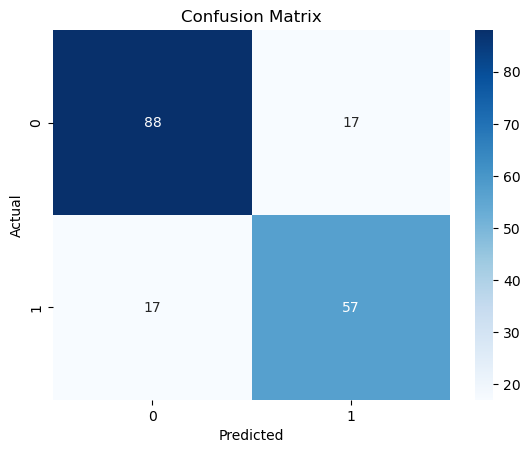

In [51]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

#### Step 12: Predict survival for a new passenger

In [52]:
new_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": 0,
    "Age": 25,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked_C": 0,
    "Embarked_Q": 0,
    "Embarked_S": 1
}])

prediction = model.predict(new_passenger[features])

if prediction[0] == 1:
    print("Passenger Survived")
else:
    print("Passenger Did Not Survive")

Passenger Did Not Survive


In [53]:
# Retrain model using complete training dataset
model.fit(X, y)

print("Model retrained on all 891 passengers!")

Model retrained on all 891 passengers!


#### Step 13: Generate predictions for Kaggle test data
This step creates a submission.csv file that can be uploaded to Kaggle.

In [54]:
test_df = pd.read_csv("test.csv")

test_df["Age"] = test_df["Age"].fillna(df["Age"].median())
test_df["Fare"] = test_df["Fare"].fillna(df["Fare"].median())

test_df["Sex"] = test_df["Sex"].map({"male": 0, "female": 1})

test_df = pd.get_dummies(
    test_df, columns=["Embarked"], dtype=int
)

X_kaggle = test_df.reindex(
    columns=features, fill_value=0
)

predictions = model.predict(X_kaggle)

submission = pd.DataFrame({
    "PassengerId": test_df["PassengerId"],
    "Survived": predictions
})

submission.to_csv("submission.csv", index=False)

print("Submission file created successfully!")
submission.head()

Submission file created successfully!


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1
